> **Disclaimer:** This notebook and any trading strategies or backtests
> developed within it are created for **educational purposes only** as
> part of CMSE 381 coursework. They do **not** constitute financial or
> investment advice. Backtested performance does not guarantee future
> results, and real markets carry risks (transaction costs, slippage,
> liquidity, data-snooping bias, etc.) that this template may not fully
> capture. The instructors, teaching staff, and Michigan State University
> assume no responsibility for financial losses resulting from applying
> these strategies to actual trading or investment decisions.

# Trend-Filtered Bollinger Strategy — Backtest Notebook

Runs your trend-filtered mean-reversion strategy on real Yahoo Finance data.

**Strategy**
- **Entry** (all must hold): trend score >= 2 (1M & 3M MAs rising) - price below lower Bollinger band (1M, 2 sigma) - Z-score(1M) < -1.5
- **Position size** by trend score: 4 -> 25%, 5 -> 50%, 6 -> 100%
- **Exit** (first to trigger): +10% profit - price crosses back above 1M MA - -8% stop-loss

Run the cells top to bottom (Shift+Enter on each).

> Not financial advice. Backtests ignore fees, slippage, and fills, and overstate real performance. Yahoo has no official API; `yfinance` scrapes internal endpoints and can break — if data comes back empty, run the upgrade cell.

## 1 · Install packages (run once)

In [1]:
# Run this once. If it errors, restart the kernel afterwards:
#   Kernel menu -> Restart
%pip install yfinance pandas numpy matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


If `yfinance` ever returns empty data later, uncomment, run this, and restart the kernel:

In [2]:
# %pip install --upgrade yfinance

## 2 · Imports and strategy functions

Just run this cell — nothing to edit.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

MA_WINDOWS = {"1W": 5,"2W": 10,"3W": 15,"1M": 21,"2M": 42,"3M": 63}

def compute_signals(close, bb_window=21, bb_sigma=1.5):
    """Moving averages, trend score, Bollinger bands, and Z-score."""

    out = pd.DataFrame(index=close.index)
    out["close"] = close

    for name, w in MA_WINDOWS.items():
        out[f"ma_{name}"] = close.rolling(w).mean()
    score = np.zeros(len(close), dtype=int)

    for name in MA_WINDOWS:
        score += (
            out[f"ma_{name}"] >
            out[f"ma_{name}"].shift(5)
        ).astype(int).values

    out["score"] = score
    mid = close.rolling(bb_window).mean()
    sd = close.rolling(bb_window).std()
    out["bb_lower"] = mid - bb_sigma * sd
    out["bb_upper"] = mid + bb_sigma * sd
    out["z"] = (close - mid) / sd
    out["trend_ok"] = out["score"] >= 4

    return out


def backtest(close, profit_target=0.10, stop_loss=0.08,
             bb_window=21, bb_sigma=1.5, z_entry=-1.5):
    """Single-position backtest. Returns (trades_df, signals_df)."""

    sig = compute_signals(close, bb_window, bb_sigma)

    # Entry conditions
    entry = (
        sig["trend_ok"]
        & (sig["score"] >= 4)
        & (sig["close"] < sig["bb_lower"])
        & (sig["z"] < z_entry)
    )
    size_by_score = {
        4: 0.25,
        5: 0.50,
        6: 1.00
    }

    trades = []

    in_pos = False
    entry_px = 0
    entry_i = 0
    entry_score = 0

    start = max(MA_WINDOWS.values())

    for i in range(start, len(close)):

        px = sig["close"].iloc[i]

        if not in_pos:

            if bool(entry.iloc[i]):

                in_pos = True
                entry_px = px
                entry_i = i
                entry_score = int(sig["score"].iloc[i])

        else:

            pnl = (px - entry_px) / entry_px
            hit_target = pnl >= profit_target
            hit_stop = pnl <= -stop_loss
            cross_ma = px > sig["ma_1M"].iloc[i]

            if hit_target or hit_stop or cross_ma:

                trades.append({
                    "entry_date": sig.index[entry_i].date(),
                    "exit_date": sig.index[i].date(),
                    "days_held": (
                        sig.index[i] - sig.index[entry_i]
                    ).days,
                    "entry_px": round(entry_px, 2),
                    "exit_px": round(px, 2),
                    "score": entry_score,
                    "size": size_by_score.get(
                        entry_score, 0.25
                    ),
                    "pnl_pct": round(pnl * 100, 2),
                    "reason": (
                        "target"
                        if hit_target
                        else "stop"
                        if hit_stop
                        else "ma_cross"
                    ),
                })

                in_pos = False

    return pd.DataFrame(trades), sig


print("Functions loaded.")

Functions loaded.


## 3 · Backtest one ticker

Change `TICKER` to anything you like, then run.

In [4]:
TICKER = "GOOGL"
PERIOD = "2y"        # "1y", "2y", "5y", "max"
PROFIT = 0.10        # +10% target
STOP   = 0.08        # -8% stop

df = yf.Ticker(TICKER).history(period=PERIOD, interval="1d")
print(f"{TICKER}: {len(df)} trading days, "
      f"{df.index[0].date()} to {df.index[-1].date()}")

trades, sig = backtest(df["Close"], profit_target=PROFIT, stop_loss=STOP)
trades

GOOGL: 502 trading days, 2024-10-30 to 2026-10-30


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

,entry_date,exit_date,days_held,entry_px,exit_px,score,size,pnl_pct,reason
0,2025-02-07,2025-02-27,20,184.26,167.52,4,0.25,-9.09,stop
1,2025-06-23,2025-06-26,3,164.61,172.94,5,0.50,5.05,ma_cross
2,2026-02-06,2026-03-11,32,322.23,308.32,5,0.50,-4.32,ma_cross


## 4 · Summary stats

In [5]:
if len(trades):
    win = (trades["pnl_pct"] > 0).mean()
    print(f"Trades:      {len(trades)}")
    print(f"Win rate:    {win:.0%}")
    print(f"Avg return:  {trades['pnl_pct'].mean():+.2f}% per trade")
    print(f"Total P&L:   {trades['pnl_pct'].sum():+.1f}% (equal weight)")
    print(f"Weighted:    {(trades['pnl_pct']*trades['size']).sum():+.1f}% (by size)")
    print()
    print("Exit reasons:")
    print(trades["reason"].value_counts().to_string())
else:
    print("No trades triggered in this window.")

print(f"\nTODAY — {TICKER}:  score {sig['score'].iloc[-1]}/6,  "
      f"Z={sig['z'].iloc[-1]:.2f},  price ${sig['close'].iloc[-1]:.2f}")

Trades:      3
Win rate:    33%
Avg return:  -2.79% per trade
Total P&L:   -8.4% (equal weight)
Weighted:    -1.9% (by size)

Exit reasons:
reason
ma_cross    2
stop        1

TODAY — GOOGL:  score 0/6,  Z=-2.60,  price $279.60


## 5 · Chart: price, Bollinger bands, and trades

Green ^ = buy, red v = sell.

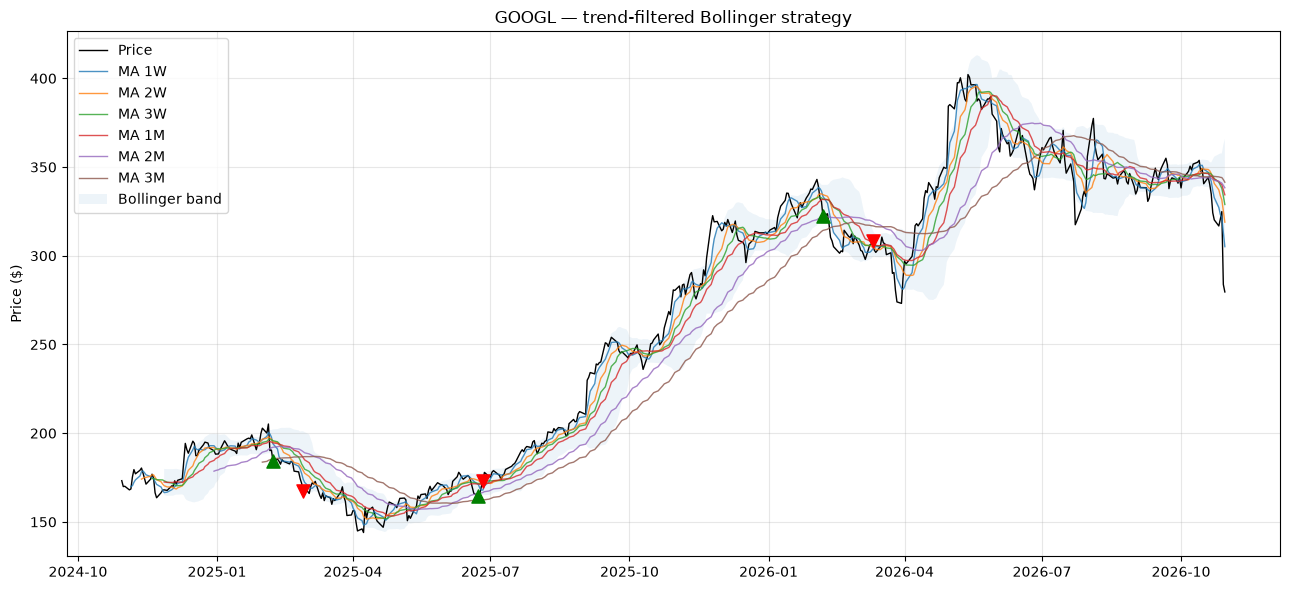

In [6]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(sig.index, sig["close"], color="black", lw=1, label="Price")

for name in MA_WINDOWS:
    ax.plot(sig.index, sig[f"ma_{name}"], lw=1, alpha=0.8, label=f"MA {name}")

ax.fill_between(sig.index, sig["bb_lower"], sig["bb_upper"], alpha=0.08, label="Bollinger band")

for _, t in trades.iterrows():
    ax.scatter(pd.Timestamp(t["entry_date"]), t["entry_px"], marker="^", color="green", s=90, zorder=5)
    ax.scatter(pd.Timestamp(t["exit_date"]), t["exit_px"], marker="v", color="red", s=90, zorder=5)

ax.set_title(f"{TICKER} — trend-filtered Bollinger strategy")
ax.set_ylabel("Price ($)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6 · Compare your whole watchlist

In [7]:
WATCHLIST = [
    "AAPL", "MSFT", "GOOGL", "AMZN", "META","IBM",
    "NVDA", "TSLA", "JPM", "BAC", "WMT",
    "KO", "PEP", "UNH", "JNJ", "XOM",
    "SPY", "QQQ", "DIA", "IWM", "SOXL",
    "DPST"
]

rows = []
for tk in WATCHLIST:
    try:
        d = yf.Ticker(tk).history(period="2y", interval="1d")
    except Exception as e:
        print(f"{tk}: fetch failed ({e})")
        continue

    if len(d) < 260:
        print(f"{tk}: not enough data, skipped")
        continue
    daily_returns = d["Close"].pct_change().dropna()
    avg_daily_return = daily_returns.mean()
    volatility = daily_returns.std()

    tr, s = backtest(d["Close"])

    cur_score = int(s["score"].iloc[-1])
    cur_z = s["z"].iloc[-1]
    below = bool(s["close"].iloc[-1] < s["bb_lower"].iloc[-1])
    ok = bool(s["trend_ok"].iloc[-1])

    signal = (
        "BUY"
        if (ok and below and cur_z < -1.5 and cur_score >= 4)
        else "no-trade" if not ok
        else "watch"
    )

    rows.append({
        "ticker": tk,
        "price": round(s["close"].iloc[-1], 2),
        "trades": len(tr),
        "win_%": round((tr["pnl_pct"] > 0).mean() * 100, 1) if len(tr) else 0.0,
        "avg_%": round(tr["pnl_pct"].mean(), 2) if len(tr) else 0.0,
        "total_%": round(tr["pnl_pct"].sum(), 1) if len(tr) else 0.0,
        "wtd_%": round((tr["pnl_pct"] * tr["size"]).sum(), 1) if len(tr) else 0.0,
        "avg_daily_return_%": round(avg_daily_return * 100, 3),
        "daily_volatility_%": round(volatility * 100, 3),

        "score": f"{cur_score}/6",
        "z": round(cur_z, 2),
        "signal": signal,
    })

pd.DataFrame(rows)

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

,ticker,price,trades,win_%,avg_%,total_%,wtd_%,avg_daily_return_%,daily_volatility_%,score,z,signal
0,AAPL,346.91,3,100.0,4.49,13.5,3.4,0.100,1.807,6/6,1.05,watch
1,MSFT,521.62,2,100.0,2.56,5.1,1.3,0.057,1.835,5/6,-1.31,watch
2,GOOGL,279.55,3,33.3,-2.79,-8.4,-1.9,0.117,2.096,0/6,-2.60,no-trade
3,AMZN,238.70,2,50.0,-0.67,-1.3,-0.7,0.066,2.175,0/6,-2.42,no-trade
4,META,621.08,2,0.0,-8.32,-16.6,-4.2,0.042,2.506,2/6,-1.45,no-trade
5,IBM,256.64,2,100.0,9.48,19.0,6.9,0.089,2.541,6/6,1.37,watch
6,NVDA,203.82,3,66.7,1.38,4.1,1.0,0.115,2.768,1/6,-1.82,no-trade
7,TSLA,399.18,2,100.0,9.93,19.9,5.0,0.153,3.627,6/6,1.35,watch
8,JPM,338.33,3,66.7,-3.28,-9.8,-2.5,0.102,1.550,4/6,1.06,watch
9,BAC,50.00,2,100.0,3.48,7.0,1.7,0.055,1.583,0/6,-1.26,no-trade


### Column guide
- **total_%** — sum of trade returns, equal weight
- **wtd_%** — sum weighted by position size (score 2/3/4 -> 25/50/100%)
- **signal** — what the strategy says *today*: BUY / watch / no-trade

### Tuning ideas
- Raise `PROFIT` to 0.15 and watch win rate fall but average winner grow
- Tighten `STOP` to 0.05 for leveraged ETFs (SOXL, DPST)
- Pass `bb_sigma=1.5` to `backtest(...)` to fire more often, `2.5` to fire rarely

Not financial advice.

## Lowest Volatility

In [8]:
results = pd.DataFrame(rows)

results.sort_values("daily_volatility_%")

,ticker,price,trades,win_%,avg_%,total_%,wtd_%,avg_daily_return_%,daily_volatility_%,score,z,signal
18,DIA,517.77,4,75.0,0.51,2.0,0.9,0.051,0.944,4/6,-0.22,watch
16,SPY,756.11,7,85.7,0.85,6.0,2.8,0.063,1.046,4/6,-2.26,BUY
11,KO,94.49,1,100.0,0.28,0.3,0.1,0.090,1.150,5/6,1.19,watch
14,JNJ,275.86,1,100.0,3.44,3.4,0.9,0.127,1.259,6/6,1.97,watch
19,IWM,278.32,3,100.0,2.60,7.8,4.0,0.059,1.324,4/6,0.21,watch
12,PEP,138.28,2,50.0,0.07,0.1,0.0,-0.012,1.390,3/6,1.62,no-trade
17,QQQ,690.09,3,66.7,0.40,1.2,0.3,0.077,1.392,1/6,-1.94,no-trade
8,JPM,338.33,3,66.7,-3.28,-9.8,-2.5,0.102,1.550,4/6,1.06,watch
15,XOM,186.87,5,100.0,2.66,13.3,6.5,0.119,1.570,6/6,1.58,watch
9,BAC,50.00,2,100.0,3.48,7.0,1.7,0.055,1.583,0/6,-1.26,no-trade


## Highest Returns

In [9]:
results.sort_values("avg_daily_return_%",ascending=False)

,ticker,price,trades,win_%,avg_%,total_%,wtd_%,avg_daily_return_%,daily_volatility_%,score,z,signal
20,SOXL,74.37,1,100.0,12.09,12.1,3.0,0.488,8.093,1/6,-1.45,no-trade
7,TSLA,399.18,2,100.0,9.93,19.9,5.0,0.153,3.627,6/6,1.35,watch
21,DPST,121.07,2,50.0,-3.72,-7.4,-9.1,0.142,4.958,4/6,1.01,watch
14,JNJ,275.86,1,100.0,3.44,3.4,0.9,0.127,1.259,6/6,1.97,watch
15,XOM,186.87,5,100.0,2.66,13.3,6.5,0.119,1.570,6/6,1.58,watch
2,GOOGL,279.55,3,33.3,-2.79,-8.4,-1.9,0.117,2.096,0/6,-2.60,no-trade
6,NVDA,203.82,3,66.7,1.38,4.1,1.0,0.115,2.768,1/6,-1.82,no-trade
8,JPM,338.33,3,66.7,-3.28,-9.8,-2.5,0.102,1.550,4/6,1.06,watch
10,WMT,124.11,3,33.3,-1.77,-5.3,-3.9,0.101,1.600,6/6,1.51,watch
0,AAPL,346.91,3,100.0,4.49,13.5,3.4,0.100,1.807,6/6,1.05,watch


## Best Return For Risk

In [10]:
results["return_per_risk"] = (results["avg_daily_return_%"] / results["daily_volatility_%"]).round(3)
results.sort_values("return_per_risk",ascending=False)

,ticker,price,trades,win_%,avg_%,total_%,wtd_%,avg_daily_return_%,daily_volatility_%,score,z,signal,return_per_risk
14,JNJ,275.86,1,100.0,3.44,3.4,0.9,0.127,1.259,6/6,1.97,watch,0.101
11,KO,94.49,1,100.0,0.28,0.3,0.1,0.090,1.150,5/6,1.19,watch,0.078
15,XOM,186.87,5,100.0,2.66,13.3,6.5,0.119,1.570,6/6,1.58,watch,0.076
8,JPM,338.33,3,66.7,-3.28,-9.8,-2.5,0.102,1.550,4/6,1.06,watch,0.066
10,WMT,124.11,3,33.3,-1.77,-5.3,-3.9,0.101,1.600,6/6,1.51,watch,0.063
16,SPY,756.11,7,85.7,0.85,6.0,2.8,0.063,1.046,4/6,-2.26,BUY,0.060
20,SOXL,74.37,1,100.0,12.09,12.1,3.0,0.488,8.093,1/6,-1.45,no-trade,0.060
2,GOOGL,279.55,3,33.3,-2.79,-8.4,-1.9,0.117,2.096,0/6,-2.60,no-trade,0.056
0,AAPL,346.91,3,100.0,4.49,13.5,3.4,0.100,1.807,6/6,1.05,watch,0.055
17,QQQ,690.09,3,66.7,0.40,1.2,0.3,0.077,1.392,1/6,-1.94,no-trade,0.055


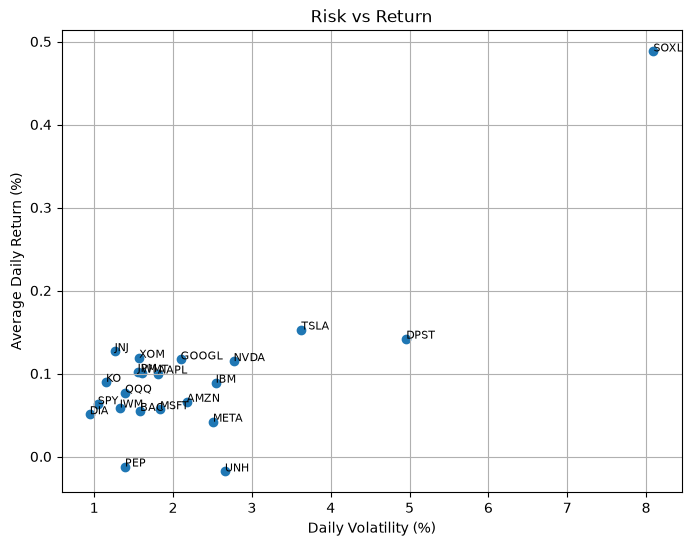

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(results["daily_volatility_%"],results["avg_daily_return_%"])

for i, row in results.iterrows():plt.text(row["daily_volatility_%"],row["avg_daily_return_%"],row["ticker"],fontsize=8)
plt.xlabel("Daily Volatility (%)")
plt.ylabel("Average Daily Return (%)")
plt.title("Risk vs Return")
plt.grid(True)

plt.show()

*JNJ and SPY offer decent returns with much lower volatility than SOXL.*

## 7.  Hold-out validation

In [12]:
TEST_START = "2026-07-01"
TEST_END = "2026-07-31"

train = df.loc[df.index < TEST_START]
test = df.loc[(df.index >= TEST_START) & (df.index <= TEST_END)]

print("Training days:", len(train))
print("Testing days :", len(test))

train_trades, train_sig = backtest(
    train["Close"],
    profit_target=PROFIT,
    stop_loss=STOP
)

print("Training trades:", len(train_trades))

Training days: 416
Testing days : 22
Training trades: 3


In [13]:
last_train = train_sig.iloc[-1]

test_signal = (
    last_train["trend_ok"]
    and last_train["score"] >= 4
    and last_train["close"] < last_train["bb_lower"]
    and last_train["z"] < -1.5
)

# What actually happened during the test period
start_price = train["Close"].iloc[-1]
end_price = test["Close"].iloc[-1]
test_return = (end_price / start_price - 1) * 100

print("Last training date:", train.index[-1].date())
print("Test period:", test.index[0].date(), "to", test.index[-1].date())
print("Score:", f"{int(last_train['score'])}/6")
print("Z-score:", round(last_train["z"], 2))
print("Strategy signal:", "BUY" if test_signal else "NO BUY")
print("Price before test period:", round(start_price, 2))
print("Price after test period:", round(end_price, 2))
print("Test-period return:", f"{test_return:.2f}%")

if test_signal:
    if test_return > 0:
        print("Result: BUY signal was successful")
    else:
        print("Result: BUY signal was unsuccessful")
else:
    print("Result: No BUY signal was generated, so there is no buy prediction to score.")

Last training date: 2026-06-30
Test period: 2026-07-01 to 2026-07-31
Score: 2/6
Z-score: -0.19
Strategy signal: NO BUY
Price before test period: 357.14
Price after test period: 355.9
Test-period return: -0.35%
Result: No BUY signal was generated, so there is no buy prediction to score.


In [14]:
### Baseline: Latest 5-Trading-Day Holdout
#This is the original short holdout test and is separate from the July 1–31 analysis below.
holdout_rows = []

for tk in WATCHLIST:
    try:
        d = yf.Ticker(tk).history(period="2y", interval="1d")
    except Exception as e:
        print(f"{tk}: fetch failed ({e})")
        continue

    if len(d) < 100:
        continue

    train = d.iloc[:-5]
    test = d.iloc[-5:]

    train_trades, train_sig = backtest(
        train["Close"],
        profit_target=PROFIT,
        stop_loss=STOP
    )

    last_train = train_sig.iloc[-1]

    test_signal = (
        last_train["trend_ok"]
        and last_train["score"] >= 4
        and last_train["close"] < last_train["bb_lower"]
        and last_train["z"] < -1.5
    )

    start_price = train["Close"].iloc[-1]
    end_price = test["Close"].iloc[-1]
    test_return = (end_price / start_price - 1) * 100

    holdout_rows.append({
        "ticker": tk,
        "score_before_test": f"{int(last_train['score'])}/6",
        "z_before_test": round(last_train["z"], 2),
        "signal_before_test": "BUY" if test_signal else "NO BUY",
        "start_price": round(start_price, 2),
        "end_price": round(end_price, 2),
        "test_return_%": round(test_return, 2),
        "buy_success": (
            "YES" if test_signal and test_return > 0
            else "NO" if test_signal and test_return <= 0
            else "-"
        )
    })

holdout_results = pd.DataFrame(holdout_rows)

holdout_results

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

,ticker,score_before_test,z_before_test,signal_before_test,start_price,end_price,test_return_%,buy_success
0,AAPL,6/6,1.63,NO BUY,347.73,346.98,-0.22,-
1,MSFT,5/6,-0.16,NO BUY,524.51,521.75,-0.53,-
2,GOOGL,1/6,-2.69,NO BUY,320.21,279.51,-12.71,-
3,AMZN,5/6,-1.09,NO BUY,248.00,238.74,-3.73,-
4,META,2/6,-2.57,NO BUY,642.62,621.10,-3.35,-
5,IBM,6/6,2.13,NO BUY,253.56,256.58,1.19,-
6,NVDA,2/6,-1.71,NO BUY,210.96,203.75,-3.42,-
7,TSLA,4/6,0.22,NO BUY,372.22,399.24,7.26,-
8,JPM,2/6,-0.64,NO BUY,331.58,338.35,2.04,-
9,BAC,0/6,-1.36,NO BUY,50.56,50.03,-1.05,-


In [15]:
buy_tests = holdout_results[
    holdout_results["signal_before_test"] == "BUY"
]

print("BUY signals:", len(buy_tests))

if len(buy_tests) > 0:
    print(
        "BUY success rate:",
        round(
            (buy_tests["buy_success"] == "YES").mean() * 100,
            1
        ),
        "%"
    )

BUY signals: 0


In [16]:
for tk in WATCHLIST:
    d = yf.Ticker(tk).history(period="2y", interval="1d")
    train = d.iloc[:-5]
    _, sig = backtest(train["Close"])

    last = sig.iloc[-1]

    print(
        tk,
        "score>=4:", last["score"] >= 4,
        "trend_ok:", bool(last["trend_ok"]),
        "below_bb:", bool(last["close"] < last["bb_lower"]),
        "z<-1.5:", bool(last["z"] < -1.5)
    )

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

AAPL score>=4: True trend_ok: True below_bb: False z<-1.5: False
MSFT score>=4: True trend_ok: True below_bb: False z<-1.5: False


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

GOOGL score>=4: False trend_ok: False below_bb: True z<-1.5: True
AMZN score>=4: True trend_ok: True below_bb: False z<-1.5: False
META score>=4: False trend_ok: False below_bb: True z<-1.5: True


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

IBM score>=4: True trend_ok: True below_bb: False z<-1.5: False
NVDA score>=4: False trend_ok: False below_bb: True z<-1.5: True


... (13 outputs left out)

IWM score>=4: False trend_ok: False below_bb: False z<-1.5: False


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

SOXL score>=4: False trend_ok: False below_bb: True z<-1.5: True
DPST score>=4: False trend_ok: False below_bb: False z<-1.5: False


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

In [17]:
SCREEN_START = "2026-07-01"
SCREEN_END = "2026-07-31"

screen_rows = []

for tk in WATCHLIST:
    d = yf.Ticker(tk).history(period="2y", interval="1d")
    _, sig = backtest(d["Close"])

    period_sig = sig.loc[SCREEN_START:SCREEN_END]

    for date, row in period_sig.iterrows():
        buy = (
            row["trend_ok"]
            and row["score"] >= 4
            and row["close"] < row["bb_lower"]
            and row["z"] < -1.5
        )

        if buy:
            screen_rows.append({
                "ticker": tk,
                "date": date.date(),
                "signal": "BUY",
                "price": round(row["close"], 2),
                "score": f"{int(row['score'])}/6",
                "z": round(row["z"], 2)
            })

july_buy_signals = pd.DataFrame(screen_rows)
july_buy_signals

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

,ticker,date,signal,price,score,z
0,IBM,2026-07-14,BUY,215.52,5/6,-2.74


In [18]:
ibm = yf.Ticker("IBM").history(period="2y", interval="1d")
_, ibm_sig = backtest(ibm["Close"])

ibm_sig.loc["2026-07-22", ["close", "score", "trend_ok", "bb_lower", "z"]]

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

close       204.304428
score                0
trend_ok         False
bb_lower    203.942847
z            -1.490019
Name: 2026-07-22 00:00:00-04:00, dtype: object

*July daily screening generated an IBM BUY on July 14.I also intentionally checked IBM’s chart and indicators on July 22 because the stock price had fallen even lower than it was on July 14, yet the strategy did not generate another BUY signal. I wanted to understand why. On July 22, IBM’s trend score had fallen to 0/6 and trend_ok was False, showing that the sharp decline had already broken the previous upward trend. The price was also still slightly above the lower Bollinger Band, and the Z-score was -1.49, just above the -1.5 threshold. This supports the idea behind the strategy: the July 14 signal represented a significant dip while the broader trend was still positive, whereas by July 22 the decline was no longer simply a dip within an uptrend.*

In [19]:
july_sell_rows = []

for tk in WATCHLIST:
    d = yf.Ticker(tk).history(period="2y", interval="1d")
    trades, sig = backtest(d["Close"])

    if len(trades) == 0:
        continue

    trades["exit_date"] = pd.to_datetime(trades["exit_date"])

    july_exits = trades[
        (trades["exit_date"] >= "2026-07-01") &
        (trades["exit_date"] <= "2026-07-31")
    ]

    for _, trade in july_exits.iterrows():
        july_sell_rows.append({
            "ticker": tk,
            "entry_date": trade["entry_date"],
            "sell_date": trade["exit_date"].date(),
            "signal": "SELL",
            "price": trade["exit_px"],
            "return_%": trade["pnl_pct"],
            "reason": trade["reason"]
        })

july_sell_signals = pd.DataFrame(july_sell_rows)
july_sell_signals

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

,ticker,entry_date,sell_date,signal,price,return_%,reason
0,AAPL,2026-06-09,2026-07-02,SELL,308.36,6.22,ma_cross
1,NVDA,2026-06-05,2026-07-08,SELL,203.89,-0.48,ma_cross


## 8. Markowitz Mean-Variance Portfolio Optimization

In [20]:
# Download price history for the watchlist
price_data = pd.DataFrame()

for tk in WATCHLIST:
    d = yf.Ticker(tk).history(period="2y", interval="1d")
    price_data[tk] = d["Close"]

price_data = price_data.dropna()

portfolio_returns = price_data.pct_change().dropna()
expected_returns = portfolio_returns.mean() * 252
cov_matrix = portfolio_returns.cov() * 252

summary = pd.DataFrame({"expected_return_%": (expected_returns * 100).round(2),"volatility_%": (portfolio_returns.std() * np.sqrt(252) * 100).round(2)})
summary

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

,expected_return_%,volatility_%
AAPL,25.17,28.68
MSFT,14.42,29.13
GOOGL,29.61,33.27
AMZN,16.66,34.53
META,10.62,39.79
IBM,22.45,40.34
NVDA,28.89,43.95
TSLA,38.54,57.58
JPM,25.69,24.60
BAC,13.87,25.12


In [21]:
from scipy.optimize import minimize

tickers = expected_returns.index.tolist()
mu = expected_returns.values
cov = cov_matrix.loc[tickers, tickers].values
n = len(tickers)

def portfolio_return(weights):
    return weights @ mu

def portfolio_volatility(weights):
    return np.sqrt(weights @ cov @ weights)

bounds = [(0, 1)] * n
sum_constraint = {"type": "eq", "fun": lambda w: np.sum(w) - 1}
x0 = np.repeat(1 / n, n)

# Find the lowest-risk portfolio first
min_var_result = minimize(portfolio_volatility,x0,method="SLSQP",bounds=bounds,constraints=[sum_constraint])

min_vol = portfolio_volatility(min_var_result.x)

print("Minimum achievable portfolio volatility:", f"{min_vol * 100:.2f}%")
volatility_caps = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60]

optimization_rows = []

for cap in volatility_caps:
    if cap < min_vol:
        continue

    constraints = [
        sum_constraint,
        {"type": "ineq", "fun": lambda w, cap=cap: cap - portfolio_volatility(w)}
    ]

    result = minimize(
        lambda w: -portfolio_return(w),
        min_var_result.x,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 1000}
    )

    if result.success:
        weights = result.x

        holdings = {
            tickers[i]: round(weights[i] * 100, 1)
            for i in range(n)
            if weights[i] > 0.01
        }

        optimization_rows.append({
            "max_volatility_%": cap * 100,
            "actual_volatility_%": portfolio_volatility(weights) * 100,
            "expected_return_%": portfolio_return(weights) * 100,
            "holdings_%": holdings
        })

markowitz_results = pd.DataFrame(optimization_rows)
markowitz_results

Minimum achievable portfolio volatility: 10.53%


,max_volatility_%,actual_volatility_%,expected_return_%,holdings_%
0,15.0,15.000010,36.652076,"{'GOOGL': 6.6, 'WMT': 2.7, 'KO': 17.5, 'JNJ': ..."
1,20.0,20.000004,43.131823,"{'KO': 3.1, 'JNJ': 62.5, 'XOM': 21.3, 'SOXL': ..."
2,25.0,25.000000,48.197238,"{'JNJ': 66.2, 'XOM': 15.7, 'SOXL': 18.2}"
3,30.0,30.000037,52.558159,"{'JNJ': 67.5, 'XOM': 9.7, 'SOXL': 22.9}"
4,35.0,35.000001,56.629633,"{'JNJ': 68.7, 'XOM': 4.1, 'SOXL': 27.2}"
5,40.0,40.000000,60.546530,"{'JNJ': 68.6, 'SOXL': 31.4}"
6,50.0,50.000000,68.045899,"{'JNJ': 60.3, 'SOXL': 39.7}"
7,60.0,60.000003,75.288848,"{'JNJ': 52.4, 'SOXL': 47.6}"


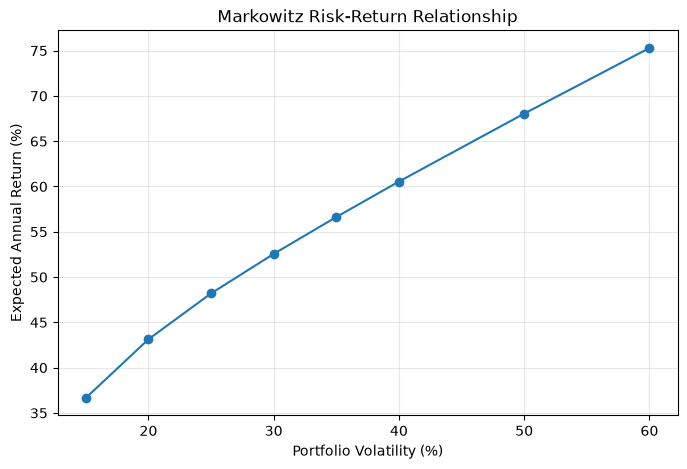

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(markowitz_results["actual_volatility_%"],markowitz_results["expected_return_%"],marker="o")
plt.xlabel("Portfolio Volatility (%)")
plt.ylabel("Expected Annual Return (%)")
plt.title("Markowitz Risk-Return Relationship")
plt.grid(True, alpha=0.3)

plt.show()

*The graph shows a clear positive relationship between portfolio risk and expected return. As the maximum allowable volatility increases, the Markowitz optimization is able to allocate more weight to higher-risk, higher-return assets, which increases the portfolio’s estimated annual return. In this analysis, the higher-risk portfolios increasingly include SOXL, which had very high historical returns but also very high volatility. Therefore, the results illustrate the risk-return tradeoff: achieving a higher expected return requires accepting greater portfolio volatility. These expected returns are annualized estimates based on historical data and should not be interpreted as guaranteed future returns.*

## 9. Microsoft ~$500 Sell and Buy-Back Analysis

In [23]:
msft = yf.Ticker("MSFT").history(period="2y", interval="1d")
msft_sig = compute_signals(msft["Close"])


msft_sig["bb_position"] = (
    (msft_sig["close"] - msft_sig["bb_lower"]) /
    (msft_sig["bb_upper"] - msft_sig["bb_lower"])
)

msft_sig["sell_signal"] = (
    (msft_sig["score"] >= 4) &
    (msft_sig["bb_position"] >= 0.95)
)

msft_sig["buy_signal"] = (
    (msft_sig["score"] >= 4) &
    (msft_sig["bb_position"] <= 0.05)
)

msft_sig.tail(15)[
    ["close", "score", "bb_lower", "bb_upper",
     "z", "bb_position", "sell_signal", "buy_signal"]
].round(3)

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

,close,score,bb_lower,bb_upper,z,bb_position,sell_signal,buy_signal
Date,,,,,,,,
2026-10-12 00:00:00-04:00,541.150,6,489.716,533.440,2.029,1.176,True,False
2026-10-13 00:00:00-04:00,543.450,6,489.302,537.477,1.872,1.124,True,False
2026-10-14 00:00:00-04:00,533.690,6,490.849,539.413,1.146,0.882,False,False
2026-10-15 00:00:00-04:00,539.440,6,493.517,541.425,1.376,0.959,True,False
2026-10-16 00:00:00-04:00,529.050,6,495.726,542.197,0.651,0.717,False,False
2026-10-19 00:00:00-04:00,533.520,6,498.855,542.852,0.864,0.788,False,False
2026-10-20 00:00:00-04:00,531.870,5,501.058,543.532,0.676,0.725,False,False
2026-10-21 00:00:00-04:00,532.950,5,504.189,543.729,0.682,0.727,False,False
2026-10-22 00:00:00-04:00,521.080,5,506.822,543.048,-0.319,0.394,False,False


In [24]:
msft_500 = msft_sig[
    (msft_sig["close"] >= 490) &
    (msft_sig["close"] <= 520)
][
    ["close", "score", "bb_lower", "bb_upper",
     "z", "bb_position", "sell_signal", "buy_signal"]
].copy()

msft_500.round(3)

,close,score,bb_lower,bb_upper,z,bb_position,sell_signal,buy_signal
Date,,,,,,,,
2025-06-26 00:00:00-04:00,492.581,6,452.631,486.093,2.082,1.194,True,False
2025-06-27 00:00:00-04:00,491.086,6,454.016,488.347,1.739,1.080,True,False
2025-06-30 00:00:00-04:00,492.541,6,455.525,490.490,1.676,1.059,True,False
2025-07-03 00:00:00-04:00,493.957,6,461.310,493.823,1.512,1.004,True,False
2025-07-07 00:00:00-04:00,492.848,6,463.443,494.882,1.306,0.935,False,False
...,...,...,...,...,...,...,...,...
2026-09-28 00:00:00-04:00,509.220,6,489.554,511.402,1.200,0.900,False,False
2026-09-29 00:00:00-04:00,508.960,6,489.860,510.660,1.255,0.918,False,False
2026-09-30 00:00:00-04:00,512.900,6,489.555,511.500,1.691,1.064,True,False


In [25]:
msft_500_sells = msft_500[
    msft_500["sell_signal"]
].copy()

msft_500_sells[
    ["close", "score", "bb_upper", "z", "bb_position"]
].round(3)

,close,score,bb_upper,z,bb_position
Date,,,,,
2025-06-26 00:00:00-04:00,492.581,6,486.093,2.082,1.194
2025-06-27 00:00:00-04:00,491.086,6,488.347,1.739,1.080
2025-06-30 00:00:00-04:00,492.541,6,490.490,1.676,1.059
2025-07-03 00:00:00-04:00,493.957,6,493.823,1.512,1.004
2025-07-09 00:00:00-04:00,498.581,6,497.516,1.604,1.035
2025-07-11 00:00:00-04:00,498.393,6,499.868,1.352,0.951
2025-07-15 00:00:00-04:00,500.869,6,502.060,1.376,0.959
2025-07-17 00:00:00-04:00,506.691,6,504.513,1.736,1.079
2025-07-18 00:00:00-04:00,505.057,6,505.443,1.456,0.985


In [26]:
buyback_rows = []

for sell_date, sell_row in msft_500_sells.iterrows():

    sell_price = sell_row["close"]

    later = msft_sig.loc[msft_sig.index > sell_date]

    buy_candidates = later[
        (later["buy_signal"]) &
        (later["close"] < sell_price)
    ]

    if len(buy_candidates) > 0:
        buy_date = buy_candidates.index[0]
        buy_price = buy_candidates.iloc[0]["close"]

        buyback_rows.append({
            "sell_date": sell_date.date(),
            "sell_price": round(sell_price, 2),
            "buy_back_date": buy_date.date(),
            "buy_back_price": round(buy_price, 2),
            "price_change_%": round((buy_price / sell_price - 1) * 100, 2)
        })

    else:
        buyback_rows.append({
            "sell_date": sell_date.date(),
            "sell_price": round(sell_price, 2),
            "buy_back_date": None,
            "buy_back_price": None,
            "price_change_%": None
        })

msft_buybacks = pd.DataFrame(buyback_rows)
msft_buybacks

,sell_date,sell_price,buy_back_date,buy_back_price,price_change_%
0,2025-06-26,492.58,2026-05-13,403.57,-18.07
1,2025-06-27,491.09,2026-05-13,403.57,-17.82
2,2025-06-30,492.54,2026-05-13,403.57,-18.06
3,2025-07-03,493.96,2026-05-13,403.57,-18.30
4,2025-07-09,498.58,2026-05-13,403.57,-19.06
5,2025-07-11,498.39,2026-05-13,403.57,-19.02
6,2025-07-15,500.87,2025-08-20,500.77,-0.02
7,2025-07-17,506.69,2025-08-20,500.77,-1.17
8,2025-07-18,505.06,2025-08-20,500.77,-0.85
9,2025-07-21,505.07,2025-08-20,500.77,-0.85


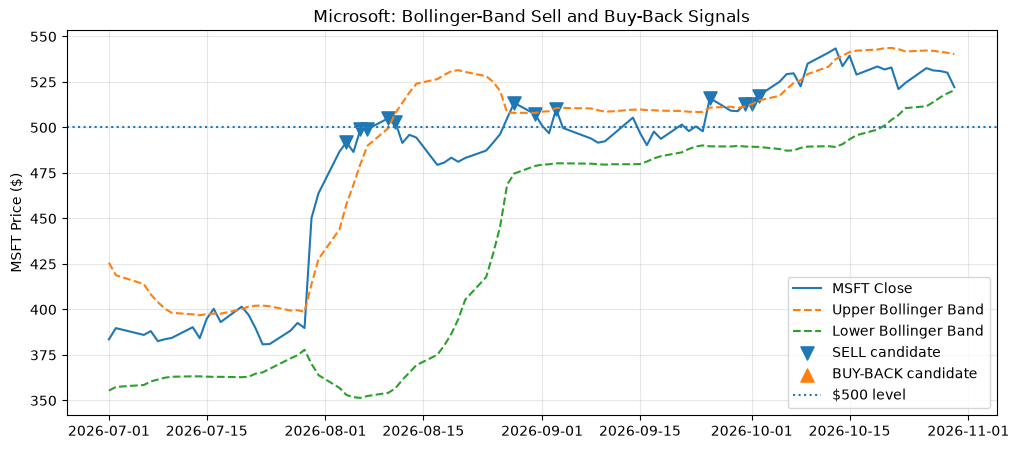

In [27]:
msft_recent = msft_sig.loc["2026-07-01":].copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(msft_recent.index, msft_recent["close"], label="MSFT Close")
ax.plot(msft_recent.index, msft_recent["bb_upper"], linestyle="--", label="Upper Bollinger Band")
ax.plot(msft_recent.index, msft_recent["bb_lower"], linestyle="--", label="Lower Bollinger Band")

sell_points = msft_recent[msft_recent["sell_signal"] &msft_recent["close"].between(490, 520)]
buy_points = msft_recent[msft_recent["buy_signal"]]

ax.scatter(
    sell_points.index,
    sell_points["close"],
    marker="v",
    s=90,
    label="SELL candidate"
)

ax.scatter(
    buy_points.index,
    buy_points["close"],
    marker="^",
    s=90,
    label="BUY-BACK candidate"
)

ax.axhline(500, linestyle=":", label="$500 level")

ax.set_title("Microsoft: Bollinger-Band Sell and Buy-Back Signals")
ax.set_ylabel("MSFT Price ($)")
ax.legend()
ax.grid(alpha=0.3)

plt.show()